# C0 Baseline Prediction

We have a pre-trained classifier C0 (DenseNet121 trained on CheXpert).
It takes a chest X-ray and outputs a **probability for each of 18 pathologies**.

Our goal is to train a Quality Control classifier (C2) that predicts:
> *"Was C0's prediction for this image correct or wrong?"*

As a **baseline** (before adding counterfactuals), we want to test:
> *"Can C2 predict correctness using ONLY C0's softmax output?"*

This notebook does the first step: **run C0 on every image and save the outputs**.

For each image we will save:
- The probability C0 assigned to Pleural Effusion
- The predicted label (1 if prob > 0.5, else 0)
- The ground truth label from CheXpert
- Whether C0 was correct (predicted == ground truth) → this becomes C2's training target

## Imports

In [1]:
# Import necessary Libraries
import os
import torch
import torchxrayvision as xrv
import torchvision
import pandas as pd
import numpy as np
from PIL import Image
from torch.utils.data import DataLoader
from tqdm import tqdm
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

/zhome/d0/a/221493/thesis/venv/lib64/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Setup

In [3]:
BASE_DIR   = "/zhome/d0/a/221493/thesis"
DATA_PATH  = os.path.join(BASE_DIR, "data/CheXpert-v1.0-small")
OUTPUT_DIR = os.path.join(BASE_DIR, "results/C0_baseline")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# The disease we are focusing on for proof of concept
TARGET_DISEASE = "Effusion"

BATCH_SIZE = 16
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cpu


## Load C0 - the DenseNet from TorchXrayVision

In [ ]:
# Load model
model = xrv.models.DenseNet(weights="densenet121-res224-chex")
model = model.to(DEVICE)
model.eval()

# ADDED THIS TO TRY AND CAPTURE THE LAST LAYER REPRESENTATION
embeddings_cache = {}
def hook_fn(module, input, output):
    embeddings_cache['last'] = output.mean(dim=[2, 3]).cpu().numpy()  # (B, 1024, 7, 7) → (B, 1024)
model.model.features.register_forward_hook(hook_fn)

In [ ]:


# Check which index corresponds to our target disease
DISEASE_IDX = model.pathologies.index(TARGET_DISEASE)
print(f"'{TARGET_DISEASE}' is at output index: {DISEASE_IDX}")
print(f"All pathologies: {model.pathologies}")

'Effusion' is at output index: 7
All pathologies: ['Atelectasis', 'Consolidation', '', 'Pneumothorax', 'Edema', '', '', 'Effusion', 'Pneumonia', '', 'Cardiomegaly', '', '', '', 'Lung Lesion', 'Fracture', 'Lung Opacity', 'Enlarged Cardiomediastinum']


## Dataset Loader (homemade to solve png reading issues)

In [5]:
class CheXpertDataset(xrv.datasets.CheX_Dataset):
    """
    Thin wrapper around the torchxrayvision CheXpert dataset.
    Adds: graceful error handling for corrupt images, and returns the file path.
    """

    def __getitem__(self, idx):
        sample = self.csv.iloc[idx]
        img_path = os.path.join(BASE_DIR, "data", sample["Path"])

        try:
            # Load image and convert to greyscale float array in [-1024, 1024] range
            img = Image.open(img_path).convert("RGB")
            img = np.array(img)
            img = xrv.datasets.normalize(img, 255)  # maps [0,255] → [-1024, 1024]
            img = img.mean(axis=2, keepdims=True)    # RGB → greyscale, keep channel dim
            img = np.transpose(img, (2, 0, 1))       # HWC → CHW for PyTorch
        except Exception as e:
            return None  # skip corrupt images

        if self.transform:
            img = self.transform(img)

        return {
            "img":  torch.tensor(img, dtype=torch.float32),
            "lab":  self.labels[idx],   # shape: [18] — one label per pathology
            "path": sample["Path"]}
        
def collate_skip_none(batch):
    """Drop any None entries (corrupt images) from the batch."""
    batch = [x for x in batch if x is not None]
    if len(batch) == 0:
        return None
    return torch.utils.data.default_collate(batch)

In [6]:
# Standard preprocessing used by torchxrayvision 224px models
transform = torchvision.transforms.Compose([
    xrv.datasets.XRayCenterCrop(),
    xrv.datasets.XRayResizer(224),
])

train_dataset = CheXpertDataset(
    imgpath=DATA_PATH,
    csvpath=os.path.join(DATA_PATH, "train.csv"),
    views=["PA", "AP"],
    transform=transform
)

valid_dataset = CheXpertDataset(
    imgpath=DATA_PATH,
    csvpath=os.path.join(DATA_PATH, "valid.csv"),
    views=["PA", "AP"],
    transform=transform
)

print(f"Train samples: {len(train_dataset)}")
print(f"Valid samples: {len(valid_dataset)}")

Train samples: 64534
Valid samples: 200


## Run C0 and Collect Predictions

For each image we record:
- `prob`: sigmoid probability for Effusion — this is C2's input feature in the baseline
- `pred`: binary prediction (1 if prob > 0.5)
- `true`: ground truth label from CheXpert
- `correct`: 1 if pred == true — this is **C2's training target**
- `margin`: |prob - 0.5| — how far from the decision boundary (an extra feature for C2)

We ignore the other 17 diseases — they are irrelevant for our Effusion QC task.

In [38]:
def run_c0(model, dataset, split_name):
    """
    Run C0 on the dataset and return a DataFrame with one row per image.
    Columns: path, prob, pred, true, correct, margin
    """
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=collate_skip_none
    )

    rows = []

    for batch in tqdm(loader, desc=f"Running C0 on {split_name}"):
        if batch is None:
            continue

        images = batch["img"].to(DEVICE)         # shape: [B, 1, 224, 224]
        labels = batch["lab"].numpy()             # shape: [B, 18]
        paths  = batch["path"]

        with torch.no_grad():
            logits = model(images)                # shape: [B, 18] — raw scores
            probs  = torch.sigmoid(logits)        # shape: [B, 18] — probabilities per disease

        # Extract only the Effusion column
        disease_probs = probs[:, DISEASE_IDX].cpu().numpy()   # shape: [B]
        disease_true  = labels[:, DISEASE_IDX]                 # shape: [B]

        for i in range(len(paths)):
            prob = disease_probs[i]
            true = disease_true[i]
            pred = int(prob > 0.5)

            rows.append({
                "path":    paths[i],
                "prob":    prob,                  # C2 baseline input feature
                "pred":    pred,                  # C0's binary decision
                "true":    true,                  # ground truth
                "correct": int(pred == true),     # C2's training TARGET (1=correct, 0=wrong)
                "margin":  abs(prob - 0.5)        # extra C2 feature: distance from decision boundary
            })

    df = pd.DataFrame(rows)

    out_path = os.path.join(OUTPUT_DIR, f"{split_name}_c0_[{TARGET_DISEASE}].csv")
    # Save to disk
    df.to_csv(out_path, index=False)
    print(f"Saved {len(df)} rows → {out_path}")

    return df

In [39]:
train_df = run_c0(model, train_dataset, "train")
valid_df = run_c0(model, valid_dataset, "valid")

Running C0 on train: 100%|██████████| 367/367 [02:08<00:00,  2.85it/s] 


Saved 693 rows → /zhome/d0/a/221493/thesis/results/C0_baseline/train_c0_[Cardiomegaly].csv


Running C0 on valid: 100%|██████████| 13/13 [00:36<00:00,  2.81s/it]

Saved 200 rows → /zhome/d0/a/221493/thesis/results/C0_baseline/valid_c0_[Cardiomegaly].csv


### The model is predicting positive for all, need to readjust the threshold to get adequate performance

## Visualize Results

In [ ]:
print("=== Sample rows ===")
print(train_df.head(10))

=== Sample rows ===
                                                path      prob  pred  true  \
0  CheXpert-v1.0-small/train/patient00001/study1/...  0.575106     1   0.0   
1  CheXpert-v1.0-small/train/patient00002/study2/...  0.678399     1   NaN   
2  CheXpert-v1.0-small/train/patient00003/study1/...  0.557501     1   NaN   
3  CheXpert-v1.0-small/train/patient00004/study1/...  0.527039     1   0.0   
4  CheXpert-v1.0-small/train/patient00005/study1/...  0.529255     1   0.0   
5  CheXpert-v1.0-small/train/patient00006/study1/...  0.579628     1   0.0   
6  CheXpert-v1.0-small/train/patient00007/study1/...  0.706738     1   NaN   
7  CheXpert-v1.0-small/train/patient00008/study1/...  0.710910     1   NaN   
8  CheXpert-v1.0-small/train/patient00009/study1/...  0.708521     1   NaN   
9  CheXpert-v1.0-small/train/patient00010/study1/...  0.501950     1   0.0   

   correct    margin  
0        0  0.075106  
1        0  0.178399  
2        0  0.057501  
3        0  0.027039  
4     

: 

In [ ]:
# How often is C0 correct vs wrong? 
# This tells us if the dataset is balanced for C2 training
print("=== Train: C0 correctness for {} ===".format(TARGET_DISEASE))
print(train_df["correct"].value_counts())
print(f"Accuracy: {train_df['correct'].mean():.3f}")

print("\n=== Valid: C0 correctness for {} ===".format(TARGET_DISEASE))
print(valid_df["correct"].value_counts())
print(f"Accuracy: {valid_df['correct'].mean():.3f}")

# How are probabilities distributed for correct vs wrong predictions?
# If C0 is well-calibrated, wrong predictions should cluster near 0.5
print("=== Probability stats for CORRECT predictions ===")
print(train_df[train_df["correct"] == 1]["prob"].describe())

print("\n=== Probability stats for WRONG predictions ===")
print(train_df[train_df["correct"] == 0]["prob"].describe())

# Check for NaN ground truth labels (CheXpert uses NaN for uncertain labels)
nan_count = train_df["true"].isna().sum()
print(f"Samples with NaN ground truth (uncertain labels): {nan_count}")

=== Train: C0 correctness for Effusion ===
correct
0    661
1     32
Name: count, dtype: int64
Accuracy: 0.046

=== Valid: C0 correctness for Effusion ===
correct
0    192
1      8
Name: count, dtype: int64
Accuracy: 0.040
=== Probability stats for CORRECT predictions ===
count    32.000000
mean      0.615482
std       0.069545
min       0.501612
25%       0.548351
50%       0.626916
75%       0.680513
max       0.714000
Name: prob, dtype: float64

=== Probability stats for WRONG predictions ===
count    661.000000
mean       0.606269
std        0.078518
min        0.500687
25%        0.524713
50%        0.615566
75%        0.684105
max        0.729557
Name: prob, dtype: float64
Samples with NaN ground truth (uncertain labels): 448


: 

## Drop the NaN (disease not mentioned) and the -1 (uncertain)

In [ ]:
# 1. Drop NaN ground truth rows — these are "uncertain" labels in CheXpert
#    and cannot be used as reliable supervision for C2
df_clean = train_df.dropna(subset=["true"]).copy()
print(f"Rows after dropping NaN: {len(df_clean)} (dropped {len(train_df) - len(df_clean)})")

# 2. Recompute correct now that NaN rows are gone
df_clean["correct"] = (df_clean["pred"] == df_clean["true"]).astype(int)
print(df_clean["correct"].value_counts())
print(f"Clean accuracy: {df_clean['correct'].mean():.3f}")

Rows after dropping NaN: 245 (dropped 448)
correct
0    213
1     32
Name: count, dtype: int64
Clean accuracy: 0.131


: 

In [ ]:
# Check if the model has pre-calibrated thresholds
print("Model operating thresholds:", model.op_threshs)

# If not None, the threshold for the target disease is:
if model.op_threshs is not None:
    disease_thresh = model.op_threshs[DISEASE_IDX]
    print(f"Calibrated threshold for {TARGET_DISEASE}: {disease_thresh}")

Model operating thresholds: tensor([0.1989, 0.0571,    nan, 0.0531, 0.1435,    nan,    nan, 0.2721, 0.0775,
           nan, 0.1971,    nan,    nan,    nan, 0.0993, 0.0927, 0.3271, 0.1089])
Calibrated threshold for Effusion: 0.1971236914396286


: 

Train after dropping NaN and uncertain: 245
Valid after dropping NaN and uncertain: 200
AUC: 0.719
Optimal threshold (Youden): 0.546


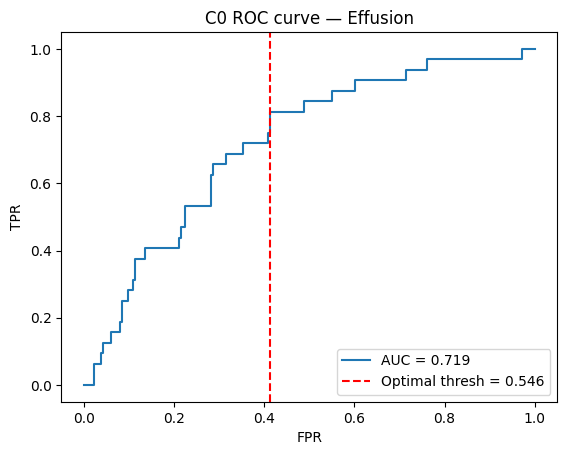

In [28]:
# Drop both NaN and uncertain (-1) labels
train_clean = train_df[train_df["true"].isin([0.0, 1.0])].copy()
valid_clean  = valid_df[valid_df["true"].isin([0.0, 1.0])].copy()

print(f"Train after dropping NaN and uncertain: {len(train_clean)}")
print(f"Valid after dropping NaN and uncertain: {len(valid_clean)}")

fpr, tpr, thresholds = roc_curve(df_clean["true"], df_clean["prob"])
auc = roc_auc_score(df_clean["true"], df_clean["prob"])

# Find the threshold closest to the top-left corner (best balance)
optimal_idx = np.argmax(tpr - fpr)
optimal_thresh = thresholds[optimal_idx]

print(f"AUC: {auc:.3f}")
print(f"Optimal threshold (Youden): {optimal_thresh:.3f}")

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.axvline(x=fpr[optimal_idx], color='red', linestyle='--', label=f"Optimal thresh = {optimal_thresh:.3f}")
plt.xlabel("FPR"); plt.ylabel("TPR")
plt.title("C0 ROC curve — Effusion")
plt.legend(); plt.show()

In [29]:
# Re-apply with the correct threshold
df_clean["pred"] = (df_clean["prob"] > optimal_thresh).astype(int)
df_clean["correct"] = (df_clean["pred"] == df_clean["true"]).astype(int)
df_clean["margin"] = abs(df_clean["prob"] - optimal_thresh)  # margin from the ACTUAL threshold

print(df_clean["pred"].value_counts())
print(f"Accuracy with optimal threshold: {df_clean['correct'].mean():.3f}")

pred
0    132
1    113
Name: count, dtype: int64
Accuracy with optimal threshold: 0.612


In [30]:
# ── Re-threshold using optimal ──────────────────────────────────────

# 1. Drop NaN ground truth rows from both splits
train_clean = train_df.dropna(subset=["true"]).copy()
valid_clean  = valid_df.dropna(subset=["true"]).copy()

# 2. Find optimal threshold on train set only
fpr, tpr, thresholds = roc_curve(train_clean["true"], train_clean["prob"])
optimal_thresh = thresholds[np.argmax(tpr - fpr)]
print(f"Optimal threshold: {optimal_thresh:.4f}")

# 3. Recompute pred, correct, margin using this threshold for both splits
for df in [train_clean, valid_clean]:
    df["pred"]    = (df["prob"] > optimal_thresh).astype(int)
    df["correct"] = (df["pred"] == df["true"]).astype(int)
    df["margin"]  = abs(df["prob"] - optimal_thresh)

# 4. Overwrite the CSVs
train_clean.to_csv(os.path.join(OUTPUT_DIR, f"train_c0_{TARGET_DISEASE}.csv"), index=False)
valid_clean.to_csv(os.path.join(OUTPUT_DIR, f"valid_c0_{TARGET_DISEASE}.csv"), index=False)

print(f"Train — {train_clean['correct'].value_counts().to_dict()} | Accuracy: {train_clean['correct'].mean():.3f}")
print(f"Valid  — {valid_clean['correct'].value_counts().to_dict()} | Accuracy: {valid_clean['correct'].mean():.3f}")

Optimal threshold: 0.5455
Train — {1: 150, 0: 95} | Accuracy: 0.612
Valid  — {0: 150, 1: 50} | Accuracy: 0.250
